# Brain-age research summary: cohorts, experiments, the best model and what mattered

One notebook for the whole EEG brain-age study on TUH (2026-10-05 → 10-16), in three phases:

* **Phase 1, TUAB only.** About 50 fine-tunes of LaBraM-base on the TUH Abnormal corpus (TUAB), aimed at
  memorization: schedule, regularizers, mixup/EMA, loss shape, codebook regularization, heads, training
  from scratch (`docs/age_overfitting_experiments.md`).
* **Phase 2, full TUH.** The same recipe on cohorts drawn from the whole TUH EEG corpus (TUEG, about
  60k recordings), plus data, input and head changes (`docs/data/tuh_cohort_eval_v1.csv`).
* **Phase 3, cross-validation.** 5-fold patient-grouped CV of the three strongest phase-2 configurations
  (`notebooks/tuh_cv_summary.ipynb`, `docs/data/cv5_eval_v2.csv`).

It answers four questions:
1. Which datasets and cohorts were used, and how they differ (Section 1).
2. Which experiments ran and which came out near the best (Section 2).
3. What exactly the best experiment does, step by step (Section 3).
4. What changed relative to LaBraM as published (Section 4), and which of those changes measurably
   moved the error (Section 5).

**Contents.** 0 Metrics and evaluation sets · 1 Data · 2 Experiments · 3 The best experiment ·
4 Changes versus the LaBraM recipe · 5 Which changes mattered · 6 Conclusions.

**Inputs.**
* In git: the registry, the two CSVs, `docs/data/line_removal_ab.json`, the configs and
  `scripts/submit_tuh_cohorts.sh`. Every phase-2 run's configuration is rebuilt from
  `labram/eval/research_summary.py::PHASE2` with the same config loader the trainer uses.
  `tests/test_research_summary.py` checks that catalog against the submit script.
* Optional, on the TUH data volume (`LABRAM_TUH_ROOT`, default `/data/datasets/EEG-public/TUH_EEG`):
  * the cohort manifests behind Section 1's counts;
  * the per-recording CV predictions behind the bootstraps (`LABRAM_CV_EVAL`).

  They stay out of git under the TUH data-use agreement. Without them those cells print a note and skip,
  and the outputs show only aggregate counts.

## 0. Metrics and evaluation sets

Every error is computed **per recording**. A recording's predicted age is the mean of its window
predictions (Eq. (3.7)), in years. For a set $S$ of recordings with true age $y_i$ and predicted age
$\hat y_i$:

$$ \mathrm{MAE}(S) = \frac{1}{|S|}\sum_{i\in S}\lvert \hat y_i - y_i\rvert \tag{0.1} $$

$$ R^2(S) = 1 - \frac{\sum_{i\in S}(\hat y_i - y_i)^2}{\sum_{i\in S}(y_i - \bar y_S)^2} \tag{0.2} $$

$$ \mathrm{bias}(S) = \frac{1}{|S|}\sum_{i\in S}(\hat y_i - y_i) \tag{0.3} $$

where $\bar y_S$ is the mean true age of $S$ (`labram/eval/cv_compare.py::metrics`). The effect of a
change from a baseline run $b$ to a variant run $v$ is

$$ \Delta\mathrm{MAE} = \mathrm{MAE}_v(S) - \mathrm{MAE}_b(S), \tag{0.4} $$

so **negative is better**. Section 5 defines when a $\Delta$ is larger than run-to-run noise.

**Evaluation sets.**
* **TUAB test:** TUAB's official evaluation set, 274 recordings of 251 patients (149 normal, 125
  abnormal). It is the same 274 recordings in every phase (checked in Section 1) and no training split
  contains any of its patients, so it is the one yardstick every run shares.
* **Val:** each run's own validation split. It differs between cohorts, so it compares runs only within
  a cohort.
* **CV test / TUEG out-of-fold:** each recording of the CV pool scored by the one fold model that never
  saw its patient.

**Caveat.** Phases 1 and 2 compared many configurations on the TUAB test set, which makes their
best single-split numbers optimistically selected. The CV numbers (Phase 3) and the TUEG out-of-fold
error were not used to choose anything.

In [1]:
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
warnings.filterwarnings("ignore")
from labram.eval import research_summary as rs
from labram.eval import cv_compare as cc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

AGE_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_age.json")
PAPER_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_paper.json")
REGISTRY = os.path.join(REPO, "docs/age_overfitting_experiments.md")
COHORT_CSV = os.path.join(REPO, "docs/data/tuh_cohort_eval_v1.csv")
CV_CSV = os.path.join(REPO, "docs/data/cv5_eval_v2.csv")
AB_JSON = os.path.join(REPO, "docs/data/line_removal_ab.json")
TUH = os.environ.get("LABRAM_TUH_ROOT", "/data/datasets/EEG-public/TUH_EEG")
CV_PREDS = os.path.join(os.environ.get("LABRAM_CV_EVAL", os.path.join(TUH, "_state/cohort_runs/cv_eval")),
                        "cv_preds.json")
HAVE_TUH = os.path.isdir(os.path.join(TUH, "cohorts"))
HAVE_PREDS = os.path.exists(CV_PREDS)

reg = rs.registry_master_table(REGISTRY)
coh = pd.read_csv(COHORT_CSV)
cv = pd.read_csv(CV_CSV)
print(f"registry: {len(reg)} phase-1 runs; cohort CSV: {coh.model.nunique()} phase-2 runs; "
      f"CV CSV: {cv.exp.nunique()} experiments x {cv.fold.nunique()} folds")
print(f"TUH data volume: {'found' if HAVE_TUH else 'not found (Section 1 counts skipped)'}; "
      f"per-recording CV predictions: {'found' if HAVE_PREDS else 'not found (bootstraps skipped)'}")

registry: 45 phase-1 runs; cohort CSV: 19 phase-2 runs; CV CSV: 3 experiments x 5 folds
TUH data volume: found; per-recording CV predictions: found


## 1. Data: every dataset and cohort

All data comes from the TUH EEG corpus. TUAB (TUH Abnormal, about 3k recordings with a normal/abnormal
label) is a subset of TUEG (the full TUH EEG corpus, about 60k recordings). The age label is parsed from
each EDF header (`labram/data/tuh_metadata.py`). Every dataset uses the same signal format:
* 23 referential channels at 200 Hz in µV, 0.1–75 Hz band-pass;
* 10 s windows;
* the first and last 60 s of each recording dropped;
* evaluation on the first 5 minutes after the trim (`labram/data/window_selection.py`).

The datasets differ in which recordings they contain, how mains interference is removed, and how
patients are split.

**Lineage.**
* `TUAB v3.0.0` (phase 1) → `TUAB v3.0.1 interp` (phase-2 control): same recordings and split, mains
  removed by 50 + 60 Hz spectrum interpolation instead of a 50 Hz notch.
* `normal_tueg_v1`, `normal_both_v1`: normal recordings only (TUEG alone; TUAB + TUEG).
* `all_both_v1` → `v2` → `v3`: every recording (normal, abnormal, unlabelled), with TUAB patients kept
  in their TUAB split.
  * `v2` gives TUEG one patient split shared by every cohort, so validation is comparable across
    cohorts.
  * `v3` adds the TUEG recordings that lack only the T1/T2 electrodes.
* `v3_compact` / `v3_cvcompact`: byte-for-byte subsets of `v3` that store only the windows a run reads
  (`dataset_maker/make_compact_cohort.py`). `cvcompact` keeps both training and evaluation windows of
  every recording, so any CV fold can use any recording.

All cohorts are built by `dataset_maker/make_cohort_dataset.py`, which drops every TUEG recording of a
TUAB-test patient and asserts that no patient is in two splits.

### Table 1.1. Datasets and cohorts

One row per dataset.

| column | meaning |
|---|---|
| `phase` | the phase that used the dataset |
| `contents` | which recordings it holds |
| `line removal` | how mains interference is removed (from the dataset's `manifest.json`) |
| `rules` | inclusion rules: `age` range in years; `≥ min` minimum recording length in minutes; `≤ k/patient` at most *k* train/val recordings per patient; `T1/T2 may be missing` |
| `TUEG split` | how TUEG patients are split; TUAB patients always keep their TUAB split |
| `used by` | the runs of Tables 2.1–2.3 trained on it |

In [2]:
DATASETS = [
    ("TUAB v3.0.0", "1", "tuab/v3.0.1/edf/legacy_v3.0.0_processed", "TUAB, all recordings (normal + abnormal)",
     "phase-1 runs (Table 2.1)"),
    ("TUAB v3.0.1 interp", "2", "tuab/v3.0.1/edf/processed_npy_interp50-60", "TUAB, all recordings", "Control"),
    ("normal_tueg_v1", "2", "cohorts/normal_tueg_v1", "TUEG normal, patients outside TUAB; no test split", "Exp2"),
    ("normal_both_v1", "2", "cohorts/normal_both_v1", "TUAB normal + TUEG normal", "Exp1, Exp1b, Exp1t, Exp1f"),
    ("all_both_v1", "2", "cohorts/all_both_v1", "TUAB + TUEG, every recording (normal / abnormal / no label)",
     "Exp3, Exp3b, Exp3q, Exp3c"),
    ("all_both_v2", "2", "cohorts/all_both_v2", "as v1, TUEG patients on the shared split",
     "Exp3v2, Exp3cond, Exp3clscond"),
    ("all_both_v3", "2", "cohorts/all_both_v3", "v2 + TUEG recordings missing only T1/T2",
     "Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"),
    ("all_both_v3_compact", "2", "cohorts/all_both_v3_compact", "v3, only the windows Exp4base reads", "Exp4basec"),
    ("all_both_v3_cvcompact", "3", "cohorts/all_both_v3_cvcompact",
     "v3, training + evaluation windows of every recording (CV pool = train + val)", "cvbase, cvctrl, cvaug"),
]


def manifest(path):
    p = os.path.join(TUH, path, "manifest.json")
    return json.load(open(p)) if os.path.exists(p) else {}


def rules(m):
    c = m.get("cohort", {})
    if not c:
        return "age 1–89 (TUAB)"
    r = [f"age {c['min_age']}–{c['max_age']}", f"≥ {c['min_minutes']:g} min", f"≤ {c['max_per_subject']}/patient"]
    if c.get("allow_missing"):
        r.append("/".join(c["allow_missing"]) + " may be missing")
    return ", ".join(r)


rows = []
for name, phase, path, contents, used in DATASETS:
    m = manifest(path) if HAVE_TUH else {}
    lr = m.get("line_removal") or ("notch:50" if "legacy" in path else "–")
    c = m.get("cohort", {})
    split = ("shared patient split v2" if c.get("patient_split") else
             ("seeded 10 % val" if c else "TUAB: seeded 20 % val, official test"))
    rows.append({"dataset": name, "phase": phase, "contents": contents, "line removal": lr,
                 "rules": rules(m) if HAVE_TUH else "–", "TUEG split": split, "used by": used})
table_1_1 = pd.DataFrame(rows)
numbered_table(table_1_1.set_index("dataset"), "1.1", "Datasets and cohorts")

,phase,contents,line removal,rules,TUEG split,used by
dataset,,,,,,
TUAB v3.0.0,1,"TUAB, all recordings (normal + abnormal)",notch:50,age 1–89 (TUAB),"TUAB: seeded 20 % val, official test",phase-1 runs (Table 2.1)
TUAB v3.0.1 interp,2,"TUAB, all recordings","interp:50,60",age 1–89 (TUAB),"TUAB: seeded 20 % val, official test",Control
normal_tueg_v1,2,"TUEG normal, patients outside TUAB; no test split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,Exp2
normal_both_v1,2,TUAB normal + TUEG normal,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,"Exp1, Exp1b, Exp1t, Exp1f"
all_both_v1,2,"TUAB + TUEG, every recording (normal / abnormal / no label)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,"Exp3, Exp3b, Exp3q, Exp3c"
all_both_v2,2,"as v1, TUEG patients on the shared split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",shared patient split v2,"Exp3v2, Exp3cond, Exp3clscond"
all_both_v3,2,v2 + TUEG recordings missing only T1/T2,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,"Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"
all_both_v3_compact,2,"v3, only the windows Exp4base reads","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,Exp4basec
all_both_v3_cvcompact,3,"v3, training + evaluation windows of every recording (CV pool = train + val)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,"cvbase, cvctrl, cvaug"


### Table 1.2. Size and composition per split

For each dataset and split:
* `recordings` and `patients`;
* `from TUAB`: recordings that are also in TUAB;
* `normal` / `abnormal` / `no label`: the recording's report status (TUEG recordings without a
  normal/abnormal report have no label);
* `age mean` and `age sd`: the true age's mean and sample standard deviation (years).

Computed from each dataset's `cohort.parquet` / `manifest.json`, or from `age_split.json` +
`age_metadata.json` for the TUAB-only datasets
(`labram/eval/research_summary.py::cohort_summary`, `tuab_split_summary`).

In [3]:
summaries, test_stems = {}, {}
if HAVE_TUH:
    for name, _, path, _, _ in DATASETS:
        d = os.path.join(TUH, path)
        if os.path.exists(os.path.join(d, "cohort.parquet")):
            c = pd.read_parquet(os.path.join(d, "cohort.parquet"))
            summaries[name] = rs.cohort_summary(c, manifest(path))
            test_stems[name] = set(c.stem[c.split == "test"])
        else:
            summaries[name] = rs.tuab_split_summary(os.path.join(d, "age_split.json"),
                                                    os.path.join(d, "age_metadata.json"))
            files = json.load(open(os.path.join(d, "age_split.json")))["files"].get("test", [])
            test_stems[name] = {os.path.basename(f).rsplit("_", 1)[0] for f in files}
    table_1_2 = pd.concat(summaries, names=["dataset", "_"]).droplevel("_").set_index("split", append=True)
    display(numbered_table(table_1_2, "1.2", "Size and composition per split", precision=1))
else:
    print("TUH data volume not found: set LABRAM_TUH_ROOT to show Table 1.2.")

In [4]:
if HAVE_TUH:
    ref = test_stems["TUAB v3.0.0"]
    same = {k: (v == ref) for k, v in test_stems.items() if v}
    print(f"TUAB test: {len(ref)} recordings; identical in every dataset with a test split: {all(same.values())}")
    print({k: v for k, v in same.items()})

TUAB test: 274 recordings; identical in every dataset with a test split: True
{'TUAB v3.0.0': True, 'TUAB v3.0.1 interp': True, 'normal_both_v1': True, 'all_both_v1': True, 'all_both_v2': True, 'all_both_v3': True, 'all_both_v3_compact': True, 'all_both_v3_cvcompact': True}


**Reading Table 1.2.**
* **Scale:** training grows from 2,145 TUAB recordings (phase 1) to 25,613 recordings of about 12k
  patients (`all_both_v3`).
* **Composition:** in the `all_both` cohorts about half the training recordings are abnormal and about
  7 % have no label.
* **Normal-only cohorts:** `normal_*` hold only normal recordings, but their test split is still the full
  TUAB test set, abnormal recordings included.
* **Test set:** the 274 TUAB test recordings are identical across datasets (the check above), so every
  TUAB test number in Sections 2–5 is on the same recordings.

### Figure 1.1. Composition and age of the training sets

* (a) Training recordings per dataset, stacked by status (normal / abnormal / no label).
* (b) Distribution of true age (years) in each dataset's training split, as a density (step histogram,
  2-year bins). Datasets with identical training sets (the `v3` copies) are drawn once.

Data volume required.

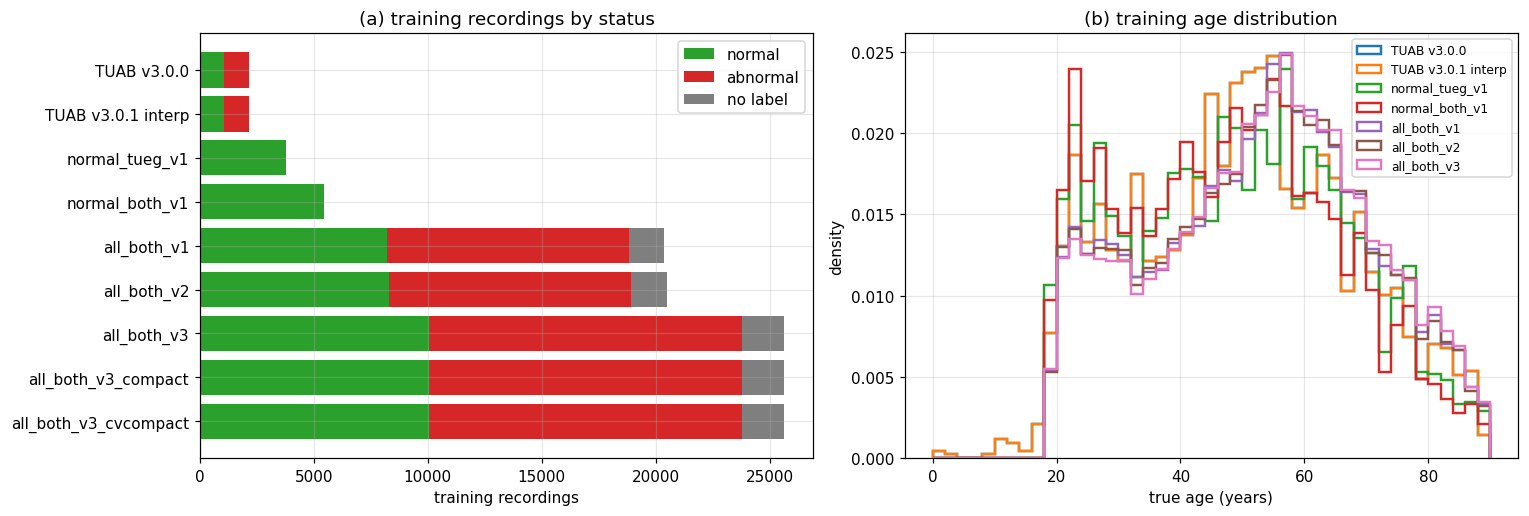

In [5]:
if HAVE_TUH:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    tr = table_1_2.xs("train", level="split")
    order = [n for n, *_ in DATASETS]
    tr = tr.reindex(order)
    left = np.zeros(len(tr))
    for col, color in (("normal", "tab:green"), ("abnormal", "tab:red"), ("no label", "tab:gray")):
        axes[0].barh(range(len(tr)), tr[col], left=left, color=color, label=col)
        left += tr[col].to_numpy()
    axes[0].set_yticks(range(len(tr)), tr.index)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("training recordings")
    axes[0].legend(loc="upper right")
    axes[0].set_title("training recordings by status")
    bins = np.arange(0, 92, 2)
    for name, _, path, _, _ in DATASETS:
        if name in ("all_both_v3_compact", "all_both_v3_cvcompact"):
            continue
        d = os.path.join(TUH, path)
        if os.path.exists(os.path.join(d, "cohort.parquet")):
            c = pd.read_parquet(os.path.join(d, "cohort.parquet"))
            ages = c.age[c.split == "train"]
        else:
            meta = json.load(open(os.path.join(d, "age_metadata.json")))["recordings"]
            files = json.load(open(os.path.join(d, "age_split.json")))["files"]["train"]
            stems = {os.path.basename(f).rsplit("_", 1)[0] for f in files}
            ages = pd.Series([meta[s]["age"] for s in stems if s in meta])
        axes[1].hist(ages, bins=bins, density=True, histtype="step", lw=1.6, label=name)
    axes[1].set_xlabel("true age (years)")
    axes[1].set_ylabel("density")
    axes[1].legend(fontsize=8)
    axes[1].set_title("training age distribution")
    panel_labels(axes)
    assert_max_columns(fig)
    fig.tight_layout()
    plt.show()

## 2. Experiments

**Phase 1 (TUAB only)** starts from scenario **D**, the default `finetune_tuab_age.json`:
* LaBraM-base with a common average reference (Eq. (3.1));
* Huber loss on the z-scored age;
* lr $10^{-4}$, 15 epochs.

**E2** shortens it to 4 epochs / 1 warmup epoch, and **M1** = E2 + mixup $\alpha = 0.4$. Every
**phase-2** run is M1 plus the change named in its row (`labram/eval/research_summary.py::M1`).
**Phase 3** cross-validates the three strongest phase-2 configurations.

### Table 2.1. Phase 1: TUAB-only runs

The experiment registry's master table (`docs/age_overfitting_experiments.md`, Table 12.1).
* `change`: relative to D unless it names another run.
* `val`, `test`: MAE (Eq. (0.1)) on the TUAB validation split (556 recordings) and on TUAB test (274),
  at the epoch with the lowest validation MAE.
* `test normal` / `test abnormal`: MAE on the two test cohorts.
* `β`: slope of the error against true age (regression to the mean; registry Eq. (1.4)).
* `best epoch` / `epochs`: the selected epoch and the schedule length.

The pre-study baseline (LaBraM fine-tuned with the original recipe adapted to regression) scored val
8.31 / test 9.04 (`docs/age_training_scenario_D.md`, Section 1).

In [6]:
t21 = reg[["run", "family", "change", "val", "test", "test_normal", "test_abnormal", "beta",
           "best_epoch", "epochs"]].rename(columns={"test_normal": "test normal", "test_abnormal": "test abnormal",
                                                    "beta": "β", "best_epoch": "best epoch"})
numbered_table(t21.set_index("run"), "2.1", "Phase 1 runs")

,family,change,val,test,test normal,test abnormal,β,best epoch,epochs
run,,,,,,,,,
A,Evaluation protocol,B with whole-recording val/test,8.29,9.03,–,–,-0.46,2.00,12.00
B,Evaluation protocol,"CAR off, 15 ep, lr 1e-4, 5-min eval (pre-D baseline)",8.40,8.91,–,–,-0.43,2.00,6.00
D,Baseline,B + CAR (finetune_tuab_age.json),7.77,8.30,–,–,-0.40,1.00,15.00
D-npy,Baseline (repro),D on the npy format,7.77,8.30,–,–,-0.40,1.00,15.00
D-cohorts,Baseline (repro),"D, local, cohort metrics",7.77,8.31,6.57,10.38,-0.40,1.00,15.00
E2,Schedule,"D, 4 ep / 1 warmup",7.68,8.25,–,–,-0.37,3.00,4.00
L1,Schedule,M12 on 12 ep / 2 warmup,7.51,8.47,6.65,10.63,-0.42,3.00,12.00
C2,Classic regularizers,"B + ld 0.5, dp 0.2, drop 0.1, wd 0.1, clip 1",12.47,13.52,–,–,-0.81,14.00,15.00
DX3,Classic regularizers,D + C2 bundle,12.83,14.90,–,–,-1.00,0.00,15.00


### Table 2.2. Phase 2: TUH cohort runs

One row per run of `docs/data/tuh_cohort_eval_v1.csv`, from `labram/eval/research_summary.py::PHASE2`:
* `cohort` (Table 1.1), `epochs` / `warmup`;
* `cond.`: ✓ if the head also receives the recording's status and pathology vector (Eq. (3.6));
* `parent` and `change`: the run it is compared with in Section 5 and what differs.

Metrics:
* `test all` / `normal` / `abnormal`: TUAB test MAE (Eq. (0.1));
* `R² normal`: Eq. (0.2) on the normal test recordings;
* `TUEG val v2`: MAE on the TUEG part of the shared v2 validation split (2,325 recordings no v2/v3
  model trained on), available only for runs scored on it.

In [7]:
def cohort_metric(model, split, source, cohort, col="MAE"):
    s = coh[(coh.model == model) & (coh.split == split) & (coh.source == source) & (coh.cohort == cohort)]
    return float(s[col].iloc[0]) if len(s) else np.nan


rows = []
for e in rs.PHASE2:
    if e.name not in set(coh.model):
        continue
    rows.append({"run": e.name, "cohort": e.cohort, "epochs": f"{e.epochs} / {e.warmup}",
                 "cond.": "✓" if e.conditions else "", "parent": e.parent, "change": e.change,
                 "test all": cohort_metric(e.name, "test", "TUAB", "all"),
                 "normal": cohort_metric(e.name, "test", "TUAB", "normal"),
                 "abnormal": cohort_metric(e.name, "test", "TUAB", "abnormal"),
                 "R² normal": cohort_metric(e.name, "test", "TUAB", "normal", "R2"),
                 "TUEG val v2": cohort_metric(e.name, "val_v2", "TUEG", "all")})
t22 = pd.DataFrame(rows).set_index("run")
numbered_table(t22, "2.2", "Phase 2 runs")

,cohort,epochs,cond.,parent,change,test all,normal,abnormal,R² normal,TUEG val v2
run,,,,,,,,,,
Control,tuab_v3.0.1_interp50-60,4 / 1,,,M1 on TUAB only (the TUAB baseline of phase 2),8.23,6.42,10.39,0.75,9.29
Exp1,normal_both_v1,4 / 1,,Control,train on normal recordings only: TUAB normal + TUEG normal,8.03,5.99,10.47,0.78,8.68
Exp2,normal_tueg_v1,4 / 1,,Exp1,TUEG normal only (no TUAB in training),8.00,6.06,10.31,0.78,8.75
Exp1b,normal_both_v1,10 / 3,,Exp1,10 epochs / 3 warmup instead of 4 / 1,8.11,6.09,10.52,0.77,8.66
Exp1t,normal_both_v1,4 / 1,,Exp1,classical EEG features as extra transformer tokens,8.80,7.17,10.73,0.70,–
Exp1f,normal_both_v1_meta,4 / 1,,Exp1,"classical EEG features only, MLP head, no EEG encoder",8.13,6.21,10.41,0.77,–
Exp3,all_both_v1,4 / 1,,Control,"add every TUEG recording (normal, abnormal, unlabelled): ~10x training data",7.26,5.57,9.28,0.80,–
Exp3b,all_both_v1,10 / 3,,Exp3,10 epochs / 3 warmup instead of 4 / 1,7.70,6.17,9.51,0.75,–
Exp3q,all_both_v1,4 / 1,,Exp3,drop windows beyond ±800 µV or with a flat channel,7.34,5.69,9.31,0.79,–


### Table 2.3. Phase 3: five-fold cross-validation

* **Folds:** the pool is `all_both_v3_cvcompact` train + val (29,035 recordings), split into 5
  patient-disjoint folds. For fold $k$, test = fold $k$, val = fold $k+1 \bmod 5$, and the other three
  train. The TUAB test set is in no fold, so each of the 5 fold models also scores it.
* **Per-fold columns:** mean ± sample sd over the 5 fold models of the MAE (Eq. (0.1)) on:
  * `CV val`: the fold's own val;
  * `CV test`: the fold's own test;
  * `TUAB test`, with `normal` and `abnormal`.
* **`ens.`:** the TUAB test MAE of the median of the 5 models' predictions (Eq. (3.8)). It needs the
  per-recording predictions.

Source: `docs/data/cv5_eval_v2.csv`.

In [8]:
def fold_stats(exp, split, source, cohort="all"):
    # mean, sample sd and count over fold models of the per-fold MAE (Eq. (0.1))
    s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
    s = s.drop_duplicates("fold")
    return s.MAE.mean(), s.MAE.std(ddof=1), len(s)


preds = cc.long_frame(cc.load_predictions(CV_PREDS)) if HAVE_PREDS else None
STATUS = {}
if HAVE_TUH:
    _lab = json.load(open(os.path.join(TUH, "tuab/v3.0.1/edf/processed_npy/age_metadata.json")))["recordings"]
    STATUS = {s: r["label"] for s, r in _lab.items()}       # TUAB recording -> normal / abnormal


def ensemble(exp, split="heldout"):
    # median over the 5 fold models per recording (Eq. (3.8)), with the TUAB status
    e = cc.ensemble(preds[preds.exp == exp], split, "median")
    e["status"] = e.stem.map(STATUS)
    return e


def ens_mae(exp, cohort="all"):
    e = ensemble(exp)
    if cohort != "all":
        e = e[e.status == cohort]
    return float(e.err.abs().mean())


rows = []
for exp in ("cvbase", "cvctrl", "cvaug"):
    r = {"run": exp, "cond.": "✓" if rs.EXPERIMENTS[exp].conditions else ""}
    for label, split, source, cohort in (("CV val", "val", "all", "all"), ("CV test", "test", "all", "all"),
                                         ("TUAB test", "heldout", "TUAB", "all"),
                                         ("normal", "heldout", "TUAB", "normal"),
                                         ("abnormal", "heldout", "TUAB", "abnormal")):
        m, sd, k = fold_stats(exp, split, source, cohort)
        r[label] = f"{m:.2f} ± {sd:.2f}"
    if preds is not None and STATUS:
        r["ens. TUAB test"] = ens_mae(exp)
        r["ens. normal"] = ens_mae(exp, "normal")
        r["ens. abnormal"] = ens_mae(exp, "abnormal")
    rows.append(r)
t23 = pd.DataFrame(rows).set_index("run")
numbered_table(t23, "2.3", "Five-fold cross-validation")

,cond.,CV val,CV test,TUAB test,normal,abnormal,ens. TUAB test,ens. normal,ens. abnormal
run,,,,,,,,,
cvbase,,8.16 ± 0.11,8.18 ± 0.15,7.49 ± 0.09,5.81 ± 0.10,9.50 ± 0.11,7.44,5.75,9.46
cvctrl,✓,8.09 ± 0.12,8.08 ± 0.13,7.28 ± 0.14,5.53 ± 0.08,9.37 ± 0.25,7.10,5.31,9.23
cvaug,✓,8.06 ± 0.13,8.06 ± 0.15,7.33 ± 0.17,5.55 ± 0.17,9.44 ± 0.18,7.23,5.43,9.37


### Figure 2.1. TUAB test MAE of every run

Every run's TUAB test MAE (Eq. (0.1), $n = 274$; normal recordings $n = 149$), in the order the runs
were made.
* (a) All test recordings.
* (b) Normal test recordings; phase-1 runs without cohort metrics are missing.

Marks:
* Phase 1 (blue), phase 2 (orange), CV (green: the mean ± sd over the 5 fold models, with a star at the
  median ensemble).
* Hollow markers: runs whose head also receives the status/pathology vector (not EEG-only).
* Collapsed runs (MAE > 11) are drawn at the top edge.
* The dashed line marks the best published TUAB normal result (Gemein et al. 2024, 6.60, normal
  recordings only), shown in (b).

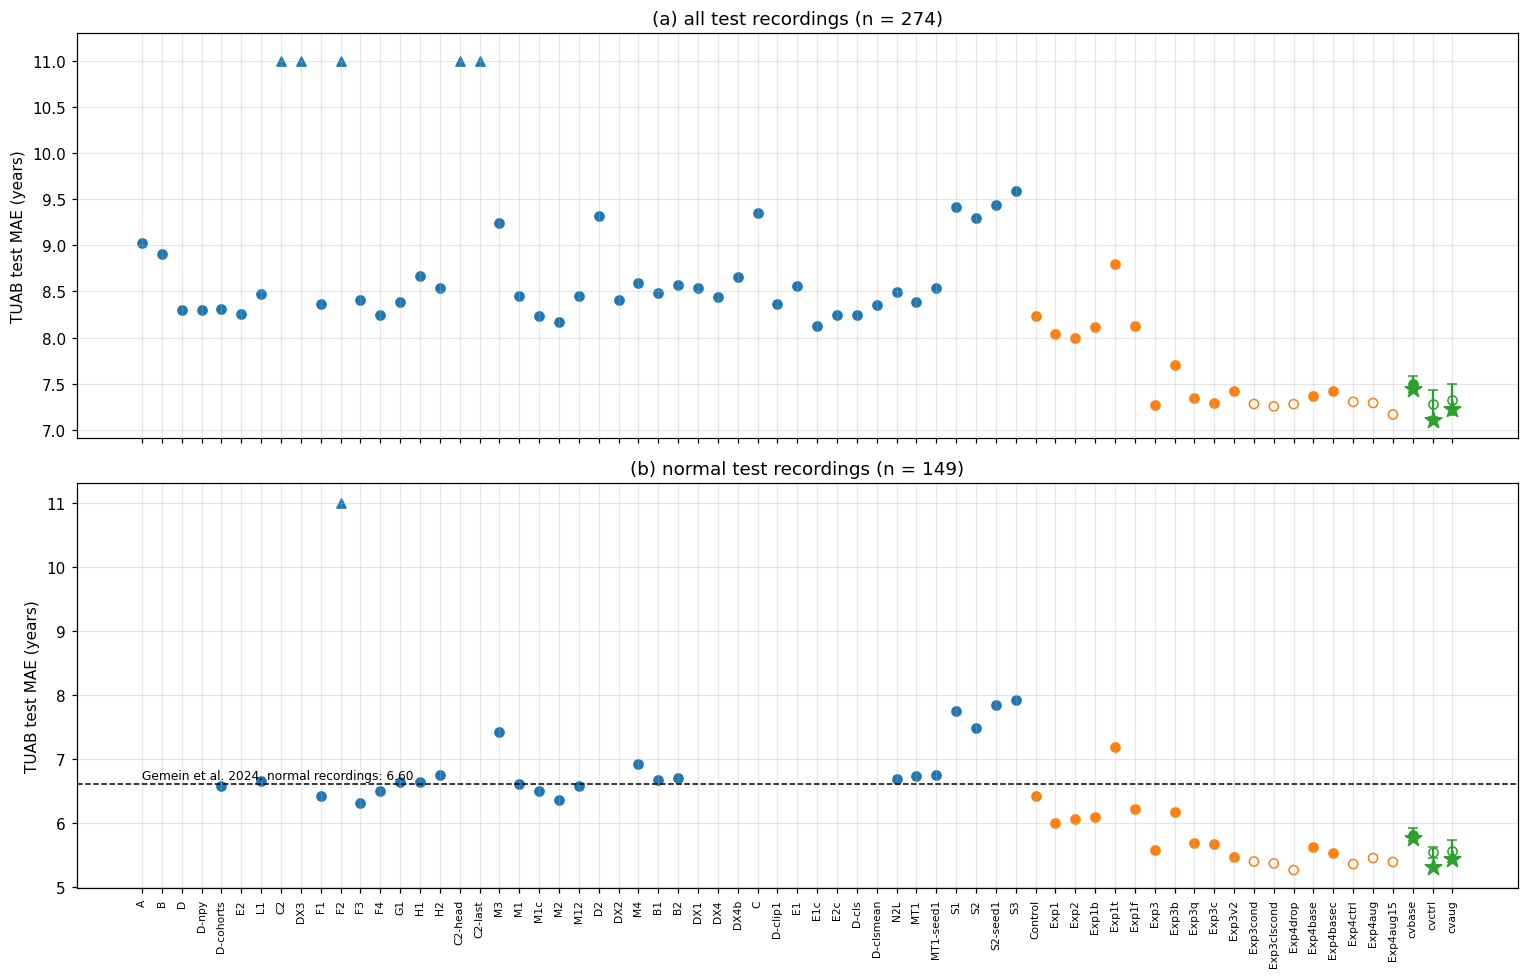

In [9]:
YMAX = 11.0
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
pts = ([("1", r.run, r.test, r.test_normal, False) for r in reg.itertuples()] +
       [("2", n, t22.loc[n, "test all"], t22.loc[n, "normal"], rs.EXPERIMENTS[n].conditions) for n in t22.index])
colors = {"1": "tab:blue", "2": "tab:orange", "3": "tab:green"}
cv_exps = ("cvbase", "cvctrl", "cvaug")
for ax, col, cohort in ((axes[0], 2, "all"), (axes[1], 3, "normal")):
    for x, p in enumerate(pts):
        y = p[col]
        if np.isnan(y):
            continue
        ax.scatter(x, min(y, YMAX), s=36, marker="^" if y > YMAX else "o",
                   facecolors="none" if p[4] else colors[p[0]], edgecolors=colors[p[0]])
    for j, exp in enumerate(cv_exps):
        x = len(pts) + j
        m, sd, _ = fold_stats(exp, "heldout", "TUAB", cohort)
        hollow = rs.EXPERIMENTS[exp].conditions
        ax.errorbar(x, m, yerr=sd, fmt="o", color=colors["3"], mfc="none" if hollow else colors["3"], capsize=3)
        if preds is not None and STATUS:
            ax.scatter(x, ens_mae(exp, cohort), marker="*", s=130, color=colors["3"], zorder=3)
    ax.set_ylim(top=YMAX + 0.3)
    ax.set_ylabel("TUAB test MAE (years)")
names = [p[1] for p in pts] + list(cv_exps)
axes[1].set_xticks(range(len(names)), names, rotation=90, fontsize=7)
axes[1].axhline(6.60, ls="--", color="k", lw=1)
axes[1].text(0, 6.68, "Gemein et al. 2024, normal recordings: 6.60", fontsize=8)
axes[0].set_title("all test recordings (n = 274)")
axes[1].set_title("normal test recordings (n = 149)")
panel_labels(axes)
assert_max_columns(fig)
fig.tight_layout()
plt.show()

### Table 2.4. The runs around the best result

The 12 runs with the lowest TUAB test MAE across all phases (Tables 2.1–2.3):
* `kind`:
  * `single split`: one run;
  * `CV mean`: mean over 5 fold models;
  * `CV ensemble`: median of 5 fold models.
* `cond.`: ✓ if the head is given the status/pathology vector.
* `test all` / `normal` / `abnormal`: MAE (Eq. (0.1)).

Ranked on `test all`, with the best EEG-only run in each kind marked `◆`.

In [10]:
rows = [{"run": r.run, "kind": "single split", "phase": "1", "cond.": "", "test all": r.test,
         "normal": r.test_normal, "abnormal": r.test_abnormal} for r in reg.itertuples()]
rows += [{"run": n, "kind": "single split", "phase": "2", "cond.": "✓" if rs.EXPERIMENTS[n].conditions else "",
          "test all": t22.loc[n, "test all"], "normal": t22.loc[n, "normal"], "abnormal": t22.loc[n, "abnormal"]}
         for n in t22.index]
for exp in ("cvbase", "cvctrl", "cvaug"):
    cond = "✓" if rs.EXPERIMENTS[exp].conditions else ""
    rows.append({"run": exp, "kind": "CV mean", "phase": "3", "cond.": cond,
                 **{k: fold_stats(exp, "heldout", "TUAB", c)[0] for k, c in
                    (("test all", "all"), ("normal", "normal"), ("abnormal", "abnormal"))}})
    if preds is not None and STATUS:
        rows.append({"run": exp, "kind": "CV ensemble", "phase": "3", "cond.": cond,
                     "test all": ens_mae(exp), "normal": ens_mae(exp, "normal"), "abnormal": ens_mae(exp, "abnormal")})
allruns = pd.DataFrame(rows)
top = allruns.sort_values("test all").head(12).copy()
for kind in top.kind.unique():
    k = allruns[(allruns.kind == kind) & (allruns["cond."] == "")].sort_values("test all")
    if len(k) and k.index[0] in top.index:
        top.loc[k.index[0], "run"] = "◆ " + top.loc[k.index[0], "run"]
numbered_table(top.set_index("run"), "2.4", "The runs around the best result")

,kind,phase,cond.,test all,normal,abnormal
run,,,,,,
cvctrl,CV ensemble,3,✓,7.10,5.31,9.23
Exp4aug15,single split,2,✓,7.17,5.38,9.29
cvaug,CV ensemble,3,✓,7.23,5.43,9.37
Exp3clscond,single split,2,✓,7.25,5.36,9.51
◆ Exp3,single split,2,,7.26,5.57,9.28
Exp4drop,single split,2,✓,7.28,5.26,9.68
Exp3cond,single split,2,✓,7.28,5.39,9.53
cvctrl,CV mean,3,✓,7.28,5.53,9.37
Exp3c,single split,2,,7.29,5.66,9.22


## 3. The best experiment

**Which run is best.** Single-split runs were compared on the TUAB test set itself (Section 0). Only
the CV runs have an error bar, and their CV test / TUEG out-of-fold errors were never used for
selection. So "best" is decided among the CV runs:

* **Best overall: `cvctrl`** (= Exp4ctrl cross-validated). It has the lowest TUAB test MAE, as a single
  fold model and as a 5-model ensemble (Table 2.3).
  * `cvaug` adds T1/T2 channel-dropout augmentation and ties with it: the differences are within noise
    in Table 5.2 (C2).
  * The simpler `cvctrl` is therefore the recommended configuration.
* **Best EEG-only: `cvbase`.** Its head sees only the EEG. `cvctrl` and `cvaug` also see the
  recording's status (normal / abnormal / no label) and 13 diagnosis flags from the clinical sheet. A
  deployed brain-age model would not have these, and published TUAB results do not use them. `cvbase` is
  therefore the number to compare with the literature (Table 3.3).

Both are LaBraM-base fine-tuned on `all_both_v3` with the M1 recipe. They differ in three settings
(Table 3.2): class-token vs mean pooling, the condition vector, and 10 vs 5 epochs.

### What the model computes

**Input and target.** The raw EEG $u$ (µV) of a 10 s window is scaled to $x = u / 100$ and cut into 1 s
patches $x_{c,a,t}$:
* channel $c = 1..C$, with $C = 23$ minus the missing T1/T2 of that recording;
* patch $a = 1..10$, sample $t = 1..200$.

The common average reference removes what all channels share (`labram/data/preprocess.py::common_average_reference`):

$$ \tilde x_{c,a,t} = x_{c,a,t} - \frac{1}{C}\sum_{c'=1}^{C} x_{c',a,t} \tag{3.1} $$

The age $y$ (years) is z-scored with the training windows' mean $\mu$ and standard deviation $\sigma$
(`labram/data/tuh_datasets.py::TUABAgeLoader._age_target`):

$$ z = \frac{y - \mu}{\sigma} \tag{3.2} $$

**Mixup.** Each training batch is blended with a permuted copy of itself, using one
$\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ per batch with $\alpha = 0.4$ (`labram/train/mixup.py::mixup_batch`).
The condition vector $c$ travels with the target, so it is blended too:

$$ \bar x = \lambda x + (1-\lambda)\,x_{\pi}, \qquad \bar z = \lambda z + (1-\lambda)\,z_{\pi}, \qquad
   \bar c = \lambda c + (1-\lambda)\,c_{\pi} \tag{3.3} $$

**Loss.** Huber loss with $\delta = 1$ on the z-scored residual $r = \hat z - \bar z$
(`labram/losses/regression.py::build_regression_criterion`):

$$ \ell_\delta(r) = \begin{cases} \tfrac12 r^2 & \lvert r\rvert \le \delta \\
   \delta\,(\lvert r\rvert - \tfrac12\delta) & \text{otherwise} \end{cases} \tag{3.4} $$

**Encoder and head.** $f_\theta$ is the 12-block LaBraM-base transformer, initialized from the
released `labram-base.pth`. Its output is $h \in \mathbb R^{200}$:
* the final LayerNorm's class token (`cvctrl`, `cvaug`);
* the mean over patch tokens (`cvbase`).

$$ h = f_\theta(\tilde x) \tag{3.5} $$

The linear head reads $h$, concatenated with a 32-d projection of the 17-d condition vector
$c \in \{0,1\}^{17}$ (3 one-hot status + 14 multi-hot pathology groups, `conditions_v1.npz`) when
conditions are on (`labram/models/neural_transformer.py`, `model.session_features=head`):

$$ \hat z = w^\top \begin{bmatrix} h \\ W_c\,c \end{bmatrix} + b, \qquad W_c \in \mathbb R^{32\times 17} \tag{3.6} $$

**Optimizer and schedule.** AdamW with weight decay 0.05. Layer-wise lr decay $\rho = 0.65$ gives block
$l$ of $L = 12$ the rate $\mathrm{lr}\cdot\rho^{\,L+1-l}$ (`labram/optim_factory.py::LayerDecayValueAssigner`).
The rate warms up linearly, then follows a cosine down to $10^{-6}$ (`labram/utils/training.py`).

**Scoring.** A recording's prediction is the de-normalized mean over its evaluation windows $W_i$ (the
first 5 minutes after the trim, 30 windows; `evaluation.agg_windows=mean`):

$$ \hat y_i = \mu + \sigma\,\frac{1}{\lvert W_i\rvert}\sum_{w\in W_i}\hat z_w \tag{3.7} $$

The fold ensemble takes the median over the $K = 5$ fold models (`labram/eval/cv_compare.py::ensemble`):

$$ \hat y_i^{\mathrm{ens}} = \operatorname{median}_{k=1..K}\,\hat y_{i,k} \tag{3.8} $$

### Table 3.1. The best configuration (`cvctrl`), step by step

One row per stage of the pipeline:
* `setting`: the configuration field;
* `cvctrl`: its value, read from the configuration rebuilt by `rs.resolve_config`
  (`finetune_tuab_age.json` + the run's overrides, exactly as the trainer builds it);
* `cvbase`: the EEG-only variant's value, where it differs;
* `equation`: where the setting appears above.

In [11]:
best = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvctrl"]))
eeg_only = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvbase"]))
paper = rs.resolve_config(PAPER_JSON)
fb, fe = rs.flatten(best.as_dict()), rs.flatten(eeg_only.as_dict())
STEPS = [
    ("data", "cohort", "data.data_path", ""),
    ("data", "5-fold CV, grouped by", "cross_validation.split_by", ""),
    ("data", "CV pool", "cross_validation.pool", ""),
    ("windows", "window length (s)", "data.window_sec", ""),
    ("windows", "trim start / end (s)", ("data.trim_start_sec", "data.trim_end_sec"), ""),
    ("windows", "train minutes per recording per epoch", "data.train_minutes_per_epoch", ""),
    ("windows", "eval minutes per recording", "data.eval_minutes", "(3.7)"),
    ("channels", "channels left out where missing", "channel_drop.channels", ""),
    ("channels", "T1/T2 dropout probability (augmentation)", "channel_drop.prob", ""),
    ("input", "common average reference", "labram_plus.common_average_reference", "(3.1)"),
    ("input", "per-patch z-scoring", "labram_plus.z_score_patches", ""),
    ("encoder", "model", "model.model", "(3.5)"),
    ("encoder", "initial weights", "finetune_checkpoint.finetune", ""),
    ("encoder", "drop path", "model.drop_path", ""),
    ("encoder", "fused attention (speed only)", "model.fused_attention", ""),
    ("head", "mean pooling (False = class token)", "model.use_mean_pooling", "(3.5)"),
    ("head", "condition vector", ("model.session_features", "data.session_features"), "(3.6)"),
    ("head", "condition projection size", "model.session_head_dim", "(3.6)"),
    ("head", "output init scale", "model.init_scale", ""),
    ("target", "task", "model.task", "(3.2)"),
    ("loss", "regression loss / δ", ("loss.regression_loss", "loss.huber_delta"), "(3.4)"),
    ("augmentation", "mixup α (on)", ("mixup.alpha", "mixup.enabled"), "(3.3)"),
    ("optimizer", "AdamW lr / batch", ("optimizer.lr", "trainer.batch_size"), ""),
    ("optimizer", "weight decay / layer decay", ("optimizer.weight_decay", "optimizer.layer_decay"), ""),
    ("schedule", "epochs / warmup", ("trainer.epochs", "optimizer.warmup_epochs"), ""),
    ("schedule", "min lr", "optimizer.min_lr", ""),
    ("selection", "checkpoint", None, "lowest val MAE (recording level)"),
    ("scoring", "window aggregation / case unit", ("evaluation.agg_windows", "evaluation.agg_case_by"), "(3.7)"),
]


def value(flat, keys):
    keys = keys if isinstance(keys, tuple) else (keys,)
    vals = [flat[k] for k in keys]
    vals = [os.path.basename(str(v).rstrip("/")) if k.endswith(("data_path", "finetune")) else v
            for k, v in zip(keys, vals)]
    return " / ".join(rs._show(v) for v in vals)


rows = []
for stage, what, keys, eq in STEPS:
    if keys is None:
        rows.append({"stage": stage, "what": what, "setting": "–", "cvctrl": eq, "cvbase": "", "equation": ""})
        continue
    vb, ve = value(fb, keys), value(fe, keys)
    rows.append({"stage": stage, "what": what, "setting": " / ".join(keys if isinstance(keys, tuple) else (keys,)),
                 "cvctrl": vb, "cvbase": "" if ve == vb else ve, "equation": eq})
numbered_table(pd.DataFrame(rows).set_index(["stage", "what"]), "3.1", "The best configuration")

### Table 3.2. The three cross-validated configurations

Every configuration field on which `cvbase`, `cvctrl` and `cvaug` disagree
(`labram/eval/research_summary.py::config_diff`, bookkeeping fields excluded).

In [12]:
cfgs = {e: rs.flatten(rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS[e])).as_dict())
        for e in ("cvbase", "cvctrl", "cvaug")}
keys = sorted(k for k in cfgs["cvbase"] if not k.startswith(rs.NON_SCIENTIFIC)
              and len({rs._show(c.get(k)) for c in cfgs.values()}) > 1)
t32 = pd.DataFrame({e: [rs._show(c.get(k)) for k in keys] for e, c in cfgs.items()}, index=pd.Index(keys, name="field"))
numbered_table(t32, "3.2", "The three cross-validated configurations")

,cvbase,cvctrl,cvaug
field,,,
channel_drop.consistency_weight,0,0,0.1
channel_drop.prob,0,0,0.2
data.session_features,,conditions_v1.npz,conditions_v1.npz
model.session_features,off,head,head
model.use_mean_pooling,True,False,False
optimizer.warmup_epochs,1,3,3
trainer.epochs,5,10,10


### Table 3.3. Results of the best experiment by evaluation set and cohort

`cvctrl` (best overall) and `cvbase` (best EEG-only), mean ± sample sd over the 5 fold models of the
MAE (Eq. (0.1)) and the mean $R^2$ (Eq. (0.2)), per evaluation set and status cohort:
* `CV val`, `CV test`: the fold's own held-out folds, TUAB and TUEG recordings together;
* `TUEG test`: the TUEG recordings of each fold's test fold;
* `TUAB test`: the official test set, $n = 274$.

$R^2$ is relative to each cohort's own age spread, so it does not compare across cohorts. The last row
gives the median ensemble (Eq. (3.8)) on the TUAB test set when the per-recording predictions are
available. For reference, the best published TUAB normal-recording result is MAE 6.60, $R^2$ 0.73
(Gemein et al. 2024, trained on TUAB normal recordings only, on its own patient-wise re-split of TUAB).

In [13]:
rows = []
for label, split, source in (("CV val", "val", "all"), ("CV test", "test", "all"), ("TUEG test", "test", "TUEG"),
                             ("TUAB test", "heldout", "TUAB")):
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": label, "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
            s = s.drop_duplicates("fold")
            r[f"{exp} MAE"] = f"{s.MAE.mean():.2f} ± {s.MAE.std(ddof=1):.2f}"
            r[f"{exp} R²"] = round(float(s.R2.mean()), 2)
        rows.append(r)
if preds is not None and STATUS:
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": "TUAB test, ensemble", "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            e = ensemble(exp)
            e = e if cohort == "all" else e[e.status == cohort]
            m = cc.metrics(e.pred, e.true)
            r[f"{exp} MAE"] = f"{m['MAE']:.2f}"
            r[f"{exp} R²"] = round(m["R2"], 2)
        rows.append(r)
numbered_table(pd.DataFrame(rows).set_index(["set", "cohort"]), "3.3", "Results of the best experiment")

## 4. Changes versus the LaBraM recipe

The reference is **LaBraM as published for TUAB**, `labram/configs/defaults/finetune_tuab_paper.json`:
* LaBraM-base fine-tuned for normal/abnormal classification, the recipe of the paper and the README;
* lr $5\cdot10^{-4}$, batch 64, 50 epochs with 5 warmup, layer decay 0.65, drop path 0.1;
* no input re-referencing;
* a 50 Hz notch in preprocessing (`dataset_maker/make_TUAB.py`).

Table 4.1 lists every configuration field the best configuration changes. Table 4.2 lists the changes
that live in the data or the code rather than the configuration. Section 5 then tests which of them
moved the error.

### Table 4.1. Configuration changes: LaBraM TUAB recipe → best configuration

Every field on which `finetune_tuab_paper.json` and `cvctrl` (Table 3.1) differ, computed by
`labram/eval/research_summary.py::config_diff`. Excluded:
* bookkeeping fields (paths, logging, infrastructure);
* fields a regression run never reads (`INERT_FOR_REGRESSION`);
* fields of a section that is off in both.

Columns:
* `group`: the part of the pipeline;
* `meaning`: what the change does;
* `evidence`: the rows of Table 5.2 that test it, where one does.

In [14]:
MEANING = {
    "data.dataset": ("task", "age regression on TUH (TUAB_AGE loader) instead of normal/abnormal", ""),
    "model.task": ("task", "scalar regression head (Huber on z-scored age, Eqs. (3.2), (3.4))", ""),
    "labram_plus.enabled": ("input", "turns on the LaBraM++ input block (Eq. (3.1))", "P1"),
    "labram_plus.z_score_patches": ("input", "LaBraM++ block with CAR only, no per-patch z-scoring", "P1"),
    "data.trim_start_sec": ("windows", "drop the first 60 s of every recording", ""),
    "data.trim_end_sec": ("windows", "drop the last 60 s of every recording", ""),
    "data.eval_minutes": ("windows", "score each recording on its first 5 minutes after the trim", "P26"),
    "data.train_minutes_per_epoch": ("windows", "5 minutes per recording per epoch, redrawn each epoch (speed)", "Q14"),
    "evaluation.agg_windows": ("scoring", "one prediction per recording = mean of its windows (Eq. (3.7))", ""),
    "mixup.enabled": ("augmentation", "mixup α 0.4 (Eq. (3.3))", "P3"),
    "optimizer.lr": ("optimizer", "2e-4 at batch 128 = 1e-4 at batch 64, linearly scaled", "Q14"),
    "trainer.batch_size": ("optimizer", "batch 128 (speed; lr scaled with it)", "Q14"),
    "optimizer.warmup_epochs": ("schedule", "3 warmup epochs", "P2, Q6, C1"),
    "trainer.epochs": ("schedule", "10 epochs instead of 50 (best epoch is early)", "P2, Q6, C1"),
    "model.use_mean_pooling": ("head", "head on the class token instead of the mean patch token", "P22, Q13, C1"),
    "model.session_features": ("head", "status + pathology vector concatenated to the feature (Eq. (3.6))", "Q12, C1"),
    "data.session_features": ("head", "the condition vectors' file (conditions_v1.npz)", "Q12, C1"),
    "channel_drop.enabled": ("channels", "per-sample handling of missing T1/T2 (needed for cohort v3)", "Q14"),
    "channel_drop.channels": ("channels", "T1/T2 are the channels that may be missing", "Q14"),
    "channel_drop.max_drop": ("channels", "up to both of T1/T2", "Q14"),
    "channel_drop.prob": ("channels", "0: no channel-dropout augmentation in cvctrl", "Q17, C2"),
    "channel_drop.consistency_weight": ("channels", "0: no consistency loss in cvctrl", "Q17, C2"),
    "cross_validation.enabled": ("protocol", "5-fold patient-grouped cross-validation", "C3"),
    "model.fused_attention": ("speed", "fused attention kernel, numerically the same model", ""),
}
t41 = rs.config_diff(paper, best, ("LaBraM recipe", "best (cvctrl)"),
                     ignore=rs.NON_SCIENTIFIC + rs.INERT_FOR_REGRESSION)
t41["group"] = t41.field.map(lambda f: MEANING.get(f, ("?", "", ""))[0])
t41["meaning"] = t41.field.map(lambda f: MEANING.get(f, ("", "(not annotated)", ""))[1])
t41["evidence"] = t41.field.map(lambda f: MEANING.get(f, ("", "", ""))[2])
missing = sorted(set(t41.field) - set(MEANING))
assert not missing, f"annotate these fields in MEANING: {missing}"
t41 = t41.sort_values(["group", "field"]).set_index(["group", "field"])
numbered_table(t41, "4.1", "Configuration changes versus the LaBraM TUAB recipe")

### Table 4.2. Changes outside the configuration

Changes in the training data, the preprocessing, the split and the code, with the Table 5.2 rows that
test them.

| change | LaBraM recipe | this study | evidence |
|---|---|---|---|
| training data | TUAB train, 2,145 recordings (≈1.6k patients) | TUAB + TUEG, 25,613 recordings (≈12k patients, `all_both_v3`) | Q1, Q3 |
| mains interference | 50 Hz notch (TUH is recorded at 60 Hz, so the line stays in) | 50 + 60 Hz spectrum interpolation | L1 |
| channels | 23 fixed channels | 23; TUEG recordings missing only T1/T2 kept, with those channels left out per sample | Q14 |
| validation split | TUAB's train split, which leaks 16 patients between train and val | patient-disjoint, seeded; one TUEG patient split shared by all cohorts; TUAB-test patients removed from TUEG | Q11 |
| label | normal/abnormal | age from the EDF header (18–89 in the TUH cohorts) | – |
| unit of evaluation | 10 s window | recording (Eq. (3.7)), first 5 minutes after the trim | P26 |
| per-patient cap | none | at most 10 train/val recordings per patient | – |
| reported model | one run | median of 5 fold models (Eq. (3.8)) | C3 |
| reproducibility | ClearML silently reseeded every tracked run to 1337 | fixed: `distributed.seed` is honoured (commit `7b9a5fe`) | – |

## 5. Which changes mattered

**Noise floor.** Two runs of the same configuration with different seeds do not give the same MAE. The
line-removal A/B study ran each of 3 preprocessing recipes $r$ with 3 seeds $s$, and each run is read
at its best-validation epoch. The pooled within-recipe sample standard deviation of a metric $m$
(`labram/eval/research_summary.py::seed_noise`) is

$$ \hat\sigma_m^2 = \frac{1}{N - R}\sum_{r}\sum_{s}\big(m_{r,s} - \bar m_r\big)^2 \tag{5.1} $$

with $N = 9$ runs and $R = 3$ recipes.

**Significance rule.** Each row of Table 5.2 compares a baseline with a variant that changes one thing
(or a named bundle), using whichever evidence exists:

* **One run each** (phases 1 and 2). The difference of two single runs has standard deviation
  $\sqrt2\,\hat\sigma$, so a change counts only if (`rs.pair_threshold`)

  $$ \lvert\Delta\mathrm{MAE}\rvert > \tau = 1.96\,\sqrt2\,\hat\sigma_{\text{test}}. \tag{5.2} $$

* **Three seeds each** (line removal, L1/L2):

  $$ \lvert \bar\Delta \rvert > 1.96\,\hat\sigma_{\text{test}}\,\sqrt{2/3}. \tag{5.3} $$

* **Five paired folds** (CV, C1/C2). Fold $k$ gives $\Delta_k$ on the same TUAB test recordings, and
  the 95 % interval is

  $$ \bar\Delta \pm t_{0.975,\,4}\,\frac{s_\Delta}{\sqrt5}, \qquad t_{0.975,\,4} = 2.776, \tag{5.4} $$

  where $\bar\Delta$ and $s_\Delta$ are the mean and sample sd of the $\Delta_k$. The change counts if
  the interval excludes 0.

* **Ensemble vs single model** (C3). A paired bootstrap over recordings (2,000 resamples,
  `cv_compare.py::bootstrap_delta_mae`) of the ensemble's absolute error against the fold models' mean
  absolute error. The change counts if its 95 % interval excludes 0.

The verdict is `improves` / `hurts` / `n.s.` (`rs.verdict`). It is judged on the TUAB test MAE of all
274 recordings, the one set every run shares; the val and cohort columns are context.

**Limits.**
* $\hat\sigma$ is measured on one configuration family (M1, TUAB) and assumed to hold for the others.
* A single-split row with $\lvert\Delta\rvert$ just under $\tau$ is not evidence of no effect, only of
  no detectable one.
* Several rows change more than one thing at once; they are marked *bundle*.

### Table 5.1. Seed-to-seed spread

The 9 age runs of the line-removal A/B study (`docs/data/line_removal_ab.json`), each at its
best-validation epoch, then the pooled standard deviation of Eq. (5.1) per metric and the single-pair
threshold $\tau$ of Eq. (5.2).
* `val_mae`: the TUAB validation split.
* `test_mae`, `test_normal_mae`, `test_abnormal_mae`: TUAB test, overall and per cohort.

In [15]:
ab_runs, SD = rs.seed_noise(AB_JSON)
TAU = rs.pair_threshold(SD["test_mae"])
display(numbered_table(ab_runs.set_index(["variant", "seed"]), "5.1", "Seed-to-seed spread"))
print("pooled seed sd (years): " + ", ".join(f"{k} {v:.3f}" for k, v in SD.items()))
print(f"single-pair threshold τ on TUAB test (Eq. 5.2): {TAU:.2f} years; "
      f"3-vs-3-seed threshold (Eq. 5.3): {1.96 * SD['test_mae'] * (2 / 3) ** 0.5:.2f} years")

pooled seed sd (years): val_mae 0.061, test_mae 0.138, test_normal_mae 0.100, test_abnormal_mae 0.194
single-pair threshold τ on TUAB test (Eq. 5.2): 0.38 years; 3-vs-3-seed threshold (Eq. 5.3): 0.22 years


### Table 5.2. Effect of each change

One row per tested change. Columns:
* `id`: the row's id, cited in Tables 4.1, 4.2 and 5.3.
* `phase`: 1 (registry, Table 2.1), 2 (Table 2.2), L (line-removal A/B, Table 5.1), C (CV, Table 2.3).
* `baseline → variant`: the two runs compared; `bundle` marks a change of several things at once.
* `Δ val`: Eq. (0.4) on the validation set the two runs share (phase 1: TUAB val; phase 2: TUEG val v2
  where both runs were scored on it).
* `Δ test`, `Δ normal`, `Δ abnormal`: Eq. (0.4) on TUAB test, overall and per cohort.
* `noise`: $\pm\tau$ (Eqs. (5.2), (5.3)) or the 95 % interval (Eq. (5.4) / bootstrap).
* `verdict`: the rule above, on `Δ test`.

In [16]:
EVIDENCE = [
    # id, phase, change, baseline, variant, bundle
    ("P1", "1", "common average reference on the input", "B", "D", False),
    ("P26", "1", "score the first 5 min instead of whole recordings", "A", "B", False),
    ("P2", "1", "4 epochs / 1 warmup instead of 15 / 2", "D", "E2", False),
    ("P3", "1", "mixup α 0.4", "E2", "M1", False),
    ("P4", "1", "C-Mixup (σ 5 y)", "E2", "M1c", False),
    ("P5", "1", "EMA weights for evaluation", "E2", "M2", False),
    ("P6", "1", "layer decay 0.5 (stronger)", "E2", "F1", False),
    ("P7", "1", "layer decay 0.75 (weaker)", "E2", "H1", False),
    ("P8", "1", "dropout 0.1", "E2", "F2", False),
    ("P9", "1", "drop path 0.2", "E2", "F3", False),
    ("P10", "1", "weight decay 0.1", "E2", "F4", False),
    ("P11", "1", "head init scale 1.0", "E2", "G1", False),
    ("P12", "1", "LoRA r16 instead of full fine-tuning", "E2", "M3", True),
    ("P13", "1", "L1 loss instead of Huber", "B", "D2", False),
    ("P14", "1", "Huber δ 2", "D", "DX2", False),
    ("P15", "1", "soft labels (σ 2.5 y)", "E2", "M4", False),
    ("P16", "1", "age-balanced loss (sqrt-inverse)", "E2", "B1", False),
    ("P17", "1", "codebook amplitude reconstruction", "D", "DX1", False),
    ("P18", "1", "codebook quantization term", "D", "DX4", False),
    ("P19", "1", "30 s windows instead of 10 s", "B", "C", False),
    ("P20", "1", "random crop", "D", "E1", False),
    ("P21", "1", "gradient clipping 1.0", "D", "D-clip1", False),
    ("P22", "1", "class token instead of mean pooling", "D", "D-cls", False),
    ("P23", "1", "[mean ; class token] concatenated", "D", "D-clsmean", False),
    ("P24", "1", "multi-task head (age + normal/abnormal)", "M1", "MT1", False),
    ("P25", "1", "pretrained LaBraM weights instead of training from scratch", "S1", "D", False),
    ("L1", "L", "50 + 60 Hz interpolation instead of 50 Hz notch", "A_notch50", "C_interp5060", False),
    ("L2", "L", "60 Hz notch instead of 50 Hz notch", "A_notch50", "B_notch60", False),
    ("Q1", "2", "add every TUEG recording (~10x data)", "Control", "Exp3", False),
    ("Q2", "2", "train on normal recordings only (TUAB + TUEG)", "Control", "Exp1", True),
    ("Q3", "2", "add abnormal + unlabelled recordings to normal-only", "Exp1", "Exp3", False),
    ("Q4", "2", "TUEG normal only (no TUAB in training)", "Exp1", "Exp2", False),
    ("Q5", "2", "10 / 3 epochs on the normal cohort", "Exp1", "Exp1b", False),
    ("Q6", "2", "10 / 3 epochs on the all cohort", "Exp3", "Exp3b", False),
    ("Q7", "2", "window rejection (±800 µV, flat channel)", "Exp3", "Exp3q", False),
    ("Q8", "2", "input clip ±800 µV", "Exp3", "Exp3c", False),
    ("Q9", "2", "classical features as transformer tokens", "Exp1", "Exp1t", False),
    ("Q10", "2", "classical features only, no EEG encoder", "Exp1", "Exp1f", False),
    ("Q11", "2", "shared TUEG patient split (v2)", "Exp3", "Exp3v2", False),
    ("Q12", "2", "status + pathology condition vectors", "Exp3v2", "Exp3cond", False),
    ("Q13", "2", "class token (with conditions)", "Exp3cond", "Exp3clscond", False),
    ("Q14", "2", "cohort v3 + missing-T1/T2 handling + speed settings", "Exp3v2", "Exp4base", True),
    ("Q15", "2", "compact copy of the cohort (reproduction)", "Exp4base", "Exp4basec", False),
    ("Q16", "2", "class token + conditions + 10 ep with early stopping", "Exp4base", "Exp4ctrl", True),
    ("Q17", "2", "T1/T2 dropout + consistency (6 vs 10 epochs)", "Exp4ctrl", "Exp4aug", True),
    ("Q18", "2", "T1/T2 dropped everywhere (21 channels) + cohort v3", "Exp3cond", "Exp4drop", True),
    ("Q19", "2", "15 / 5 epochs with early stopping (aug)", "Exp4aug", "Exp4aug15", False),
    ("C1", "C", "class token + conditions + 10 / 3 epochs (CV)", "cvbase", "cvctrl", True),
    ("C2", "C", "T1/T2 dropout + consistency λ 0.1 (CV)", "cvctrl", "cvaug", False),
    ("C3", "C", "median of 5 fold models instead of one (cvctrl)", "cvctrl single", "cvctrl ensemble", False),
    ("C3b", "C", "median of 5 fold models instead of one (cvbase)", "cvbase single", "cvbase ensemble", False),
]
R = reg.set_index("run")
ab = ab_runs.groupby("variant")[["val_mae", "test_mae", "test_normal_mae", "test_abnormal_mae"]].mean()
T3 = 1.96 * SD["test_mae"] * (2 / 3) ** 0.5


def fold_deltas(a, b, split="heldout", source="TUAB", cohort="all"):
    def per_fold(e):
        s = cv[(cv.exp == e) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
        return s.drop_duplicates("fold").set_index("fold").MAE
    d = (per_fold(b) - per_fold(a)).dropna()
    half = 2.776 * d.std(ddof=1) / np.sqrt(len(d))
    return float(d.mean()), float(d.mean() - half), float(d.mean() + half), int((d < 0).sum()), len(d)


rows = []
for eid, phase, change, a, b, bundle in EVIDENCE:
    r = {"id": eid, "phase": phase, "change": change + (" (bundle)" if bundle else ""), "baseline → variant": f"{a} → {b}"}
    lo = hi = None
    if phase == "1":
        r.update({"Δ val": R.loc[b, "val"] - R.loc[a, "val"], "Δ test": R.loc[b, "test"] - R.loc[a, "test"],
                  "Δ normal": R.loc[b, "test_normal"] - R.loc[a, "test_normal"],
                  "Δ abnormal": R.loc[b, "test_abnormal"] - R.loc[a, "test_abnormal"]})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif phase == "L":
        r.update({"Δ val": ab.loc[b, "val_mae"] - ab.loc[a, "val_mae"], "Δ test": ab.loc[b, "test_mae"] - ab.loc[a, "test_mae"],
                  "Δ normal": ab.loc[b, "test_normal_mae"] - ab.loc[a, "test_normal_mae"],
                  "Δ abnormal": ab.loc[b, "test_abnormal_mae"] - ab.loc[a, "test_abnormal_mae"]})
        r["noise"], thr = f"± {T3:.2f}", T3
    elif phase == "2":
        g = lambda m, sp, so, c: cohort_metric(m, sp, so, c)
        r.update({"Δ val": g(b, "val_v2", "TUEG", "all") - g(a, "val_v2", "TUEG", "all"),
                  "Δ test": g(b, "test", "TUAB", "all") - g(a, "test", "TUAB", "all"),
                  "Δ normal": g(b, "test", "TUAB", "normal") - g(a, "test", "TUAB", "normal"),
                  "Δ abnormal": g(b, "test", "TUAB", "abnormal") - g(a, "test", "TUAB", "abnormal")})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif eid in ("C1", "C2"):
        m, lo, hi, wins, k = fold_deltas(a, b)
        r.update({"Δ val": fold_deltas(a, b, "val", "all")[0], "Δ test": m,
                  "Δ normal": fold_deltas(a, b, cohort="normal")[0], "Δ abnormal": fold_deltas(a, b, cohort="abnormal")[0]})
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}], better in {wins}/{k} folds", None
    else:                                       # C3: ensemble vs the single fold models
        exp = a.split()[0]
        if preds is None or not STATUS:
            r.update({"Δ test": np.nan, "noise": "needs per-recording predictions"})
            rows.append(r)
            continue
        e = ensemble(exp).set_index("stem")
        single = preds[(preds.exp == exp) & (preds.split == "heldout")].assign(ae=lambda x: x.err.abs())
        mean_ae = single.groupby("stem").ae.mean().loc[e.index]
        bs = cc.bootstrap_delta_mae(e.err.to_numpy(), mean_ae.to_numpy())
        def by(c):
            m = e.status == c
            return float(e.err[m].abs().mean() - mean_ae[m].mean())
        r.update({"Δ test": bs["dMAE"], "Δ normal": by("normal"), "Δ abnormal": by("abnormal")})
        lo, hi = bs["lo"], bs["hi"]
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}] (bootstrap)", None
    r["verdict"] = rs.verdict(r["Δ test"], thr if thr is not None else 0.0, lo, hi)
    rows.append(r)
t52 = pd.DataFrame(rows).set_index("id")
numbered_table(t52, "5.2", "Effect of each change")

,phase,change,baseline → variant,Δ val,Δ test,Δ normal,Δ abnormal,noise,verdict
id,,,,,,,,,
P1,1,common average reference on the input,B → D,-0.63,-0.61,–,–,± 0.38,improves
P26,1,score the first 5 min instead of whole recordings,A → B,0.11,-0.12,–,–,± 0.38,n.s.
P2,1,4 epochs / 1 warmup instead of 15 / 2,D → E2,-0.09,-0.05,–,–,± 0.38,n.s.
P3,1,mixup α 0.4,E2 → M1,-0.22,0.20,–,–,± 0.38,n.s.
P4,1,C-Mixup (σ 5 y),E2 → M1c,-0.14,-0.02,–,–,± 0.38,n.s.
P5,1,EMA weights for evaluation,E2 → M2,-0.10,-0.08,–,–,± 0.38,n.s.
P6,1,layer decay 0.5 (stronger),E2 → F1,0.06,0.11,–,–,± 0.38,n.s.
P7,1,layer decay 0.75 (weaker),E2 → H1,0.03,0.42,–,–,± 0.38,hurts
P8,1,dropout 0.1,E2 → F2,5.57,6.92,–,–,± 0.38,hurts


### Figure 5.1. Effect sizes

$\Delta$ test (Eq. (0.4), TUAB test, all 274 recordings; negative is better) for every row of Table 5.2.
* (a) Phase 1, TUAB-only runs.
* (b) Line removal, phase 2 and CV.

Error bars and colour:
* The bar is the noise band: $\pm\tau$ for single and 3-seed pairs, the 95 % interval for CV and
  ensemble rows.
* Green = `improves`, red = `hurts`, grey = `n.s.`
* Effects beyond ±2 years (collapsed runs) are drawn at the edge with their value written next to them.

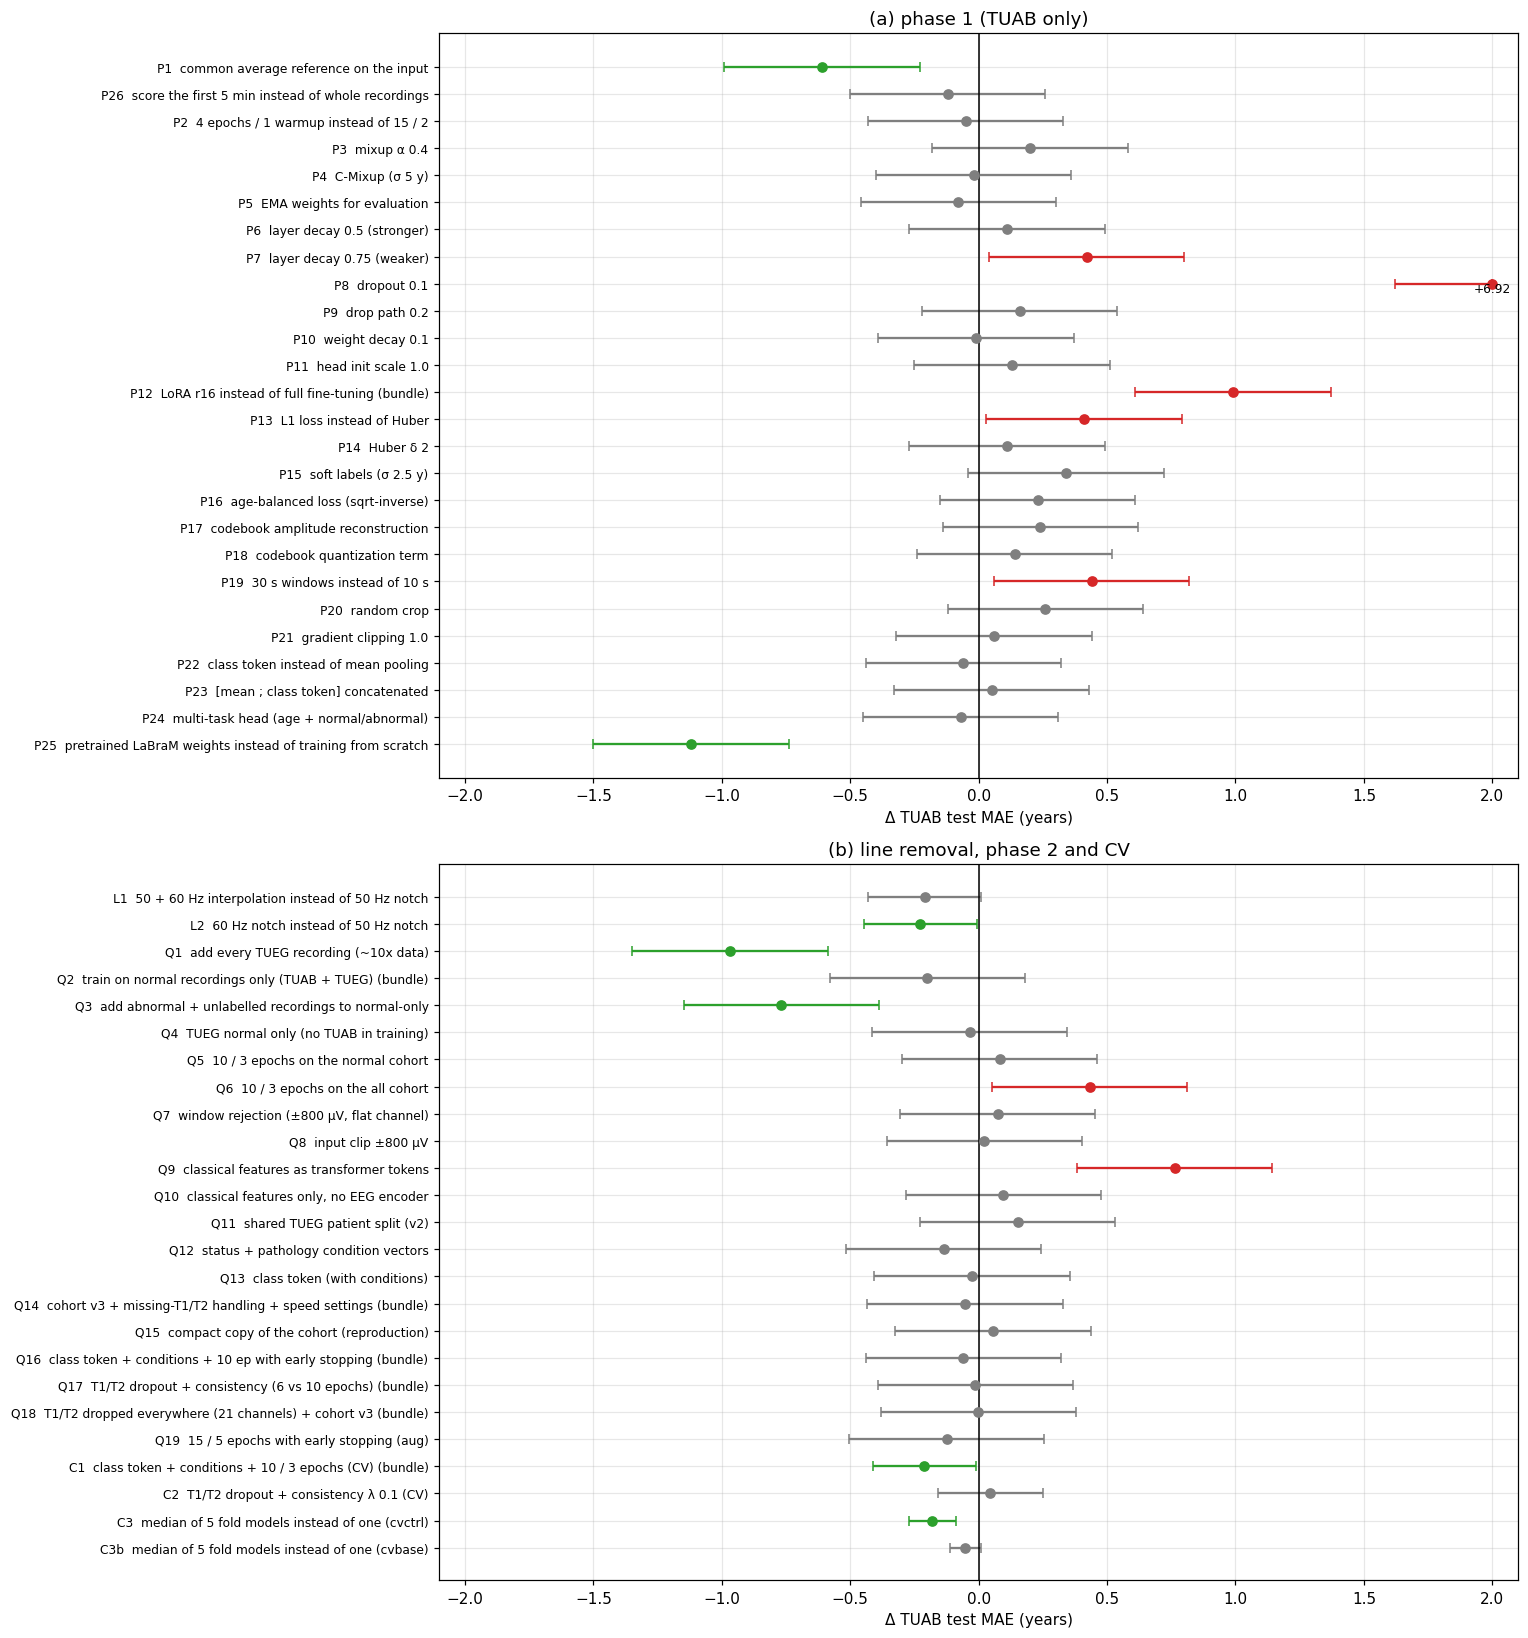

In [17]:
def band(row):
    s = row["noise"]
    if isinstance(s, str) and s.startswith("["):
        lo, hi = (float(v) for v in s[1:s.index("]")].split(","))
        return row["Δ test"] - lo, hi - row["Δ test"]
    w = float(s.split()[-1]) if isinstance(s, str) and s.startswith("±") else 0.0
    return w, w


COL = {"improves": "tab:green", "hurts": "tab:red", "n.s.": "tab:gray", "–": "tab:gray"}
LIM = 2.0
fig, axes = plt.subplots(2, 1, figsize=(14, 15), gridspec_kw={"height_ratios": [26, 25]})
for ax, phases, title in ((axes[0], ("1",), "phase 1 (TUAB only)"), (axes[1], ("L", "2", "C"), "line removal, phase 2 and CV")):
    sub = t52[t52.phase.isin(phases) & t52["Δ test"].notna()]
    for y, (eid, row) in enumerate(sub.iterrows()):
        d = row["Δ test"]
        lo, hi = band(row)
        x = float(np.clip(d, -LIM, LIM))
        ax.errorbar(x, y, xerr=[[min(lo, x + LIM)], [min(hi, LIM - x)]], fmt="o", color=COL[row.verdict], capsize=3)
        if abs(d) > LIM:
            ax.text(x, y + 0.3, f"{d:+.2f}", fontsize=8, ha="center")
    ax.set_yticks(range(len(sub)), [f"{i}  {c}" for i, c in zip(sub.index, sub.change)], fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color="k", lw=1)
    ax.set_xlim(-LIM - 0.1, LIM + 0.1)
    ax.set_xlabel("Δ TUAB test MAE (years)")
    ax.set_title(title)
panel_labels(axes)
assert_max_columns(fig)
fig.tight_layout()
plt.show()

### Table 5.3. Changes versus LaBraM: which mattered

The summary the study was after. One row per change from the LaBraM TUAB recipe to the best
configuration (Tables 4.1 and 4.2), with:
* `estimate`: the Table 5.2 row that isolates the change best and its $\Delta$ test;
* `verdict`: that row's verdict;
* `in best config`: whether the change is part of `cvctrl`.

`not isolated` means no run changes it alone, so its effect is not known.

In [18]:
SUMMARY = [
    ("training data: TUAB → TUAB + TUEG (~10x recordings)", "Q1", "yes"),
    ("abnormal and unlabelled recordings in training", "Q3", "yes"),
    ("pretrained LaBraM weights (vs from scratch)", "P25", "yes"),
    ("common average reference on the input", "P1", "yes"),
    ("mains: 50 + 60 Hz interpolation instead of 50 Hz notch", "L1", "yes"),
    ("ensemble: median of the 5 fold models", "C3", "yes"),
    ("class token + condition vectors + 10 epochs (bundle)", "C1", "yes"),
    ("condition vectors alone (single split)", "Q12", "yes"),
    ("class-token pooling alone (TUAB / TUH)", "P22", "yes"),
    ("short schedule (4–10 epochs instead of 15–50)", "P2", "yes"),
    ("mixup α 0.4", "P3", "yes"),
    ("cohort v3 + missing-T1/T2 handling + speed settings (bundle)", "Q14", "yes"),
    ("5-minute evaluation window", "P26", "yes"),
    ("T1/T2 channel-dropout augmentation", "C2", "no (cvaug)"),
    ("longer schedule on the full cohort (10 epochs)", "Q6", "no"),
    ("dropout 0.1", "P8", "no"),
    ("weaker layer decay 0.75", "P7", "no"),
    ("LoRA instead of full fine-tuning", "P12", "no"),
    ("30 s windows", "P19", "no"),
    ("classical features as tokens", "Q9", "no"),
    ("L1 loss", "P13", "no"),
    ("weight decay, drop path, layer decay 0.5, head init", "P10", "no"),
    ("loss shape: Huber δ 2, soft labels, age-balanced", "P16", "no"),
    ("codebook regularization", "P18", "no"),
    ("signal QC: window rejection / ±800 µV clip", "Q7", "no"),
    ("multi-task head", "P24", "no"),
    ("trim 60 s at both ends; lr 1e-4 (vs 5e-4); batch 128", None, "yes"),
]
rows = []
for change, eid, used in SUMMARY:
    if eid is None:
        rows.append({"change vs LaBraM": change, "estimate": "–", "Δ test": np.nan, "verdict": "not isolated",
                     "in best config": used})
        continue
    r = t52.loc[eid]
    rows.append({"change vs LaBraM": change, "estimate": f"{eid}: {r['baseline → variant']}", "Δ test": r["Δ test"],
                 "verdict": r["verdict"], "in best config": used})
t53 = pd.DataFrame(rows).set_index("change vs LaBraM")
numbered_table(t53, "5.3", "Changes versus LaBraM: which mattered")

,estimate,Δ test,verdict,in best config
change vs LaBraM,,,,
training data: TUAB → TUAB + TUEG (~10x recordings),Q1: Control → Exp3,-0.97,improves,yes
abnormal and unlabelled recordings in training,Q3: Exp1 → Exp3,-0.77,improves,yes
pretrained LaBraM weights (vs from scratch),P25: S1 → D,-1.12,improves,yes
common average reference on the input,P1: B → D,-0.61,improves,yes
mains: 50 + 60 Hz interpolation instead of 50 Hz notch,L1: A_notch50 → C_interp5060,-0.21,n.s.,yes
ensemble: median of the 5 fold models,C3: cvctrl single → cvctrl ensemble,-0.18,improves,yes
class token + condition vectors + 10 epochs (bundle),C1: cvbase → cvctrl,-0.21,improves,yes
condition vectors alone (single split),Q12: Exp3v2 → Exp3cond,-0.14,n.s.,yes
class-token pooling alone (TUAB / TUH),P22: D → D-cls,-0.06,n.s.,yes


## 6. Conclusions

Generated from the tables above, so they stay in step with the data when the notebook is re-run.

In [19]:
v = t52.verdict
imp, hurt = t52[v == "improves"], t52[v == "hurts"]
m = lambda exp, c="all": fold_stats(exp, "heldout", "TUAB", c)
lines = [
    f"* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is {SD['test_mae']:.2f} years (Table 5.1), so two "
    f"single runs must differ by more than {TAU:.2f} years to count (Eq. (5.2)). Of {len(t52)} tested changes, "
    f"{len(imp)} improve, {len(hurt)} hurt and {int((v == 'n.s.').sum())} are within noise (Table 5.2).",
    "* **What improved the error (Table 5.2):** " + "; ".join(
        f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in imp.sort_values("Δ test").iterrows()) + ".",
    "* **What hurt:** " + "; ".join(f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in hurt.sort_values("Δ test").iterrows()) + ".",
    f"* **Best configuration: `cvctrl`.** TUAB test MAE {m('cvctrl')[0]:.2f} ± {m('cvctrl')[1]:.2f} per fold model "
    f"(normal {m('cvctrl', 'normal')[0]:.2f}, abnormal {m('cvctrl', 'abnormal')[0]:.2f}; Table 3.3). Its head is given "
    "the status/pathology vector.",
    f"* **Best EEG-only: `cvbase`.** {m('cvbase')[0]:.2f} ± {m('cvbase')[1]:.2f} per fold model, normal recordings "
    f"{m('cvbase', 'normal')[0]:.2f}, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, "
    "different split and training data).",
]
if preds is not None and STATUS:
    lines.append(f"* **Ensembles.** The median of the 5 fold models scores {ens_mae('cvctrl'):.2f} (`cvctrl`) and "
                 f"{ens_mae('cvbase'):.2f} (`cvbase`) on the TUAB test, normal {ens_mae('cvbase', 'normal'):.2f} (`cvbase`).")
lines += [
    "* **Most of the gain over LaBraM comes from data.** The largest effects are:",
    "  * more and more varied training recordings (Q1, Q3);",
    "  * pretrained weights (P25);",
    "  * the common average reference (P1).",
    "  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).",
    "* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal "
    "ones in every configuration (Tables 2.2, 3.3).",
]
display(Markdown("\n".join(lines)))

* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is 0.14 years (Table 5.1), so two single runs must differ by more than 0.38 years to count (Eq. (5.2)). Of 51 tested changes, 7 improve, 7 hurt and 37 are within noise (Table 5.2).
* **What improved the error (Table 5.2):** P25 pretrained LaBraM weights instead of training from scratch (-1.12); Q1 add every TUEG recording (~10x data) (-0.97); Q3 add abnormal + unlabelled recordings to normal-only (-0.77); P1 common average reference on the input (-0.61); L2 60 Hz notch instead of 50 Hz notch (-0.23); C1 class token + conditions + 10 / 3 epochs (CV) (bundle) (-0.21); C3 median of 5 fold models instead of one (cvctrl) (-0.18).
* **What hurt:** P13 L1 loss instead of Huber (+0.41); P7 layer decay 0.75 (weaker) (+0.42); Q6 10 / 3 epochs on the all cohort (+0.43); P19 30 s windows instead of 10 s (+0.44); Q9 classical features as transformer tokens (+0.76); P12 LoRA r16 instead of full fine-tuning (bundle) (+0.99); P8 dropout 0.1 (+6.92).
* **Best configuration: `cvctrl`.** TUAB test MAE 7.28 ± 0.14 per fold model (normal 5.53, abnormal 9.37; Table 3.3). Its head is given the status/pathology vector.
* **Best EEG-only: `cvbase`.** 7.49 ± 0.09 per fold model, normal recordings 5.81, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, different split and training data).
* **Ensembles.** The median of the 5 fold models scores 7.10 (`cvctrl`) and 7.44 (`cvbase`) on the TUAB test, normal 5.75 (`cvbase`).
* **Most of the gain over LaBraM comes from data.** The largest effects are:
  * more and more varied training recordings (Q1, Q3);
  * pretrained weights (P25);
  * the common average reference (P1).
  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).
* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal ones in every configuration (Tables 2.2, 3.3).

**Caveats.**
* **Selection on test:** phases 1 and 2 chose among configurations on the TUAB test set, so their best
  single-split numbers are optimistic. The CV and TUEG out-of-fold numbers are not.
* **Bundles:** C1, Q14, Q16, Q17 and Q18 change several things at once, so their parts are not
  separately known.
* **Condition vectors:** `cvctrl` and `cvaug` use the status/pathology vector at test time. Only `cvbase`
  is comparable with EEG-only brain-age models.
* **Noise floor scope:** it comes from one configuration family (M1 on TUAB) and is assumed to transfer
  to the larger cohorts.